# SC04 Step 2 - Scenario Inspection
This notebook runs the reproducible generator, inspects the generated traffic states and shows the validation result.

**Honesty note:** all 10,000 rows are *generated* scenarios, not real observations.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from generate_scenarios import run_generator, SEED
from validate_data import check_dataframe

valid_df, invalid_df = run_generator()
print("Seed:", SEED)
print("Valid scenarios:", valid_df.shape)
print("Invalid test rows:", invalid_df.shape)

Seed: 42
Valid scenarios: (10000, 9)
Invalid test rows: (120, 10)


In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "generated" / "traffic_scenarios_10000.csv")
print("Columns:", list(df.columns))
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows (ignoring ID):", int(df.drop(columns="state_id").duplicated().sum()))
print("Duplicate IDs:", int(df["state_id"].duplicated().sum()))
display(df.head())

Columns: ['state_id', 'queue_ns', 'queue_ew', 'density_ns_pct', 'density_ew_pct', 'max_wait_ns_sec', 'max_wait_ew_sec', 'emergency_direction', 'scenario_type']

Missing values per column:
state_id               0
queue_ns               0
queue_ew               0
density_ns_pct         0
density_ew_pct         0
max_wait_ns_sec        0
max_wait_ew_sec        0
emergency_direction    0
scenario_type          0
dtype: int64

Duplicate rows (ignoring ID): 0
Duplicate IDs: 0


,state_id,queue_ns,queue_ew,density_ns_pct,density_ew_pct,max_wait_ns_sec,max_wait_ew_sec,emergency_direction,scenario_type
0,SCN-00001,1,0,100.0,0.0,1,1,none,boundary
1,SCN-00002,21,10,36.9,13.4,109,64,none,normal
2,SCN-00003,21,21,37.3,37.6,78,108,none,normal
3,SCN-00004,4,24,5.7,37.3,34,72,none,normal
4,SCN-00005,17,5,30.5,4.7,74,20,none,normal


In [3]:
print("Scenario mix:")
print(df["scenario_type"].value_counts())
print("\nEmergency direction counts:")
print(df["emergency_direction"].value_counts())
print("\nSummary statistics:")
display(df.describe().round(1))

Scenario mix:
scenario_type
normal       5000
boundary     1500
stress       1500
difficult    1500
emergency     500
Name: count, dtype: int64

Emergency direction counts:
emergency_direction
none    8725
NS       662
EW       613
Name: count, dtype: int64

Summary statistics:


,queue_ns,queue_ew,density_ns_pct,density_ew_pct,max_wait_ns_sec,max_wait_ew_sec
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,19.7,19.3,34.2,34.0,117.3,116.4
std,17.9,17.7,30.7,30.7,95.2,94.9
min,0.0,0.0,0.0,0.0,0.0,0.0
25%,6.0,6.0,10.5,10.1,46.0,45.0
50%,14.0,14.0,25.3,25.5,85.0,85.0
75%,25.0,25.0,46.9,45.8,191.0,193.0
max,60.0,60.0,100.0,100.0,300.0,300.0


In [4]:
errors = check_dataframe(df.copy())
print("Validation errors on 10,000 valid scenarios:", errors)
assert not errors
print("VALIDATION PASSED: generated scenarios are valid.")

rejected = sum(1 for i in range(len(invalid_df)) if check_dataframe(invalid_df.iloc[[i]].copy()))
print(f"EXPECTED FAIL: {rejected} of {len(invalid_df)} invalid rows were rejected")
assert rejected == len(invalid_df)

Validation errors on 10,000 valid scenarios: []
VALIDATION PASSED: generated scenarios are valid.


EXPECTED FAIL: 120 of 120 invalid rows were rejected


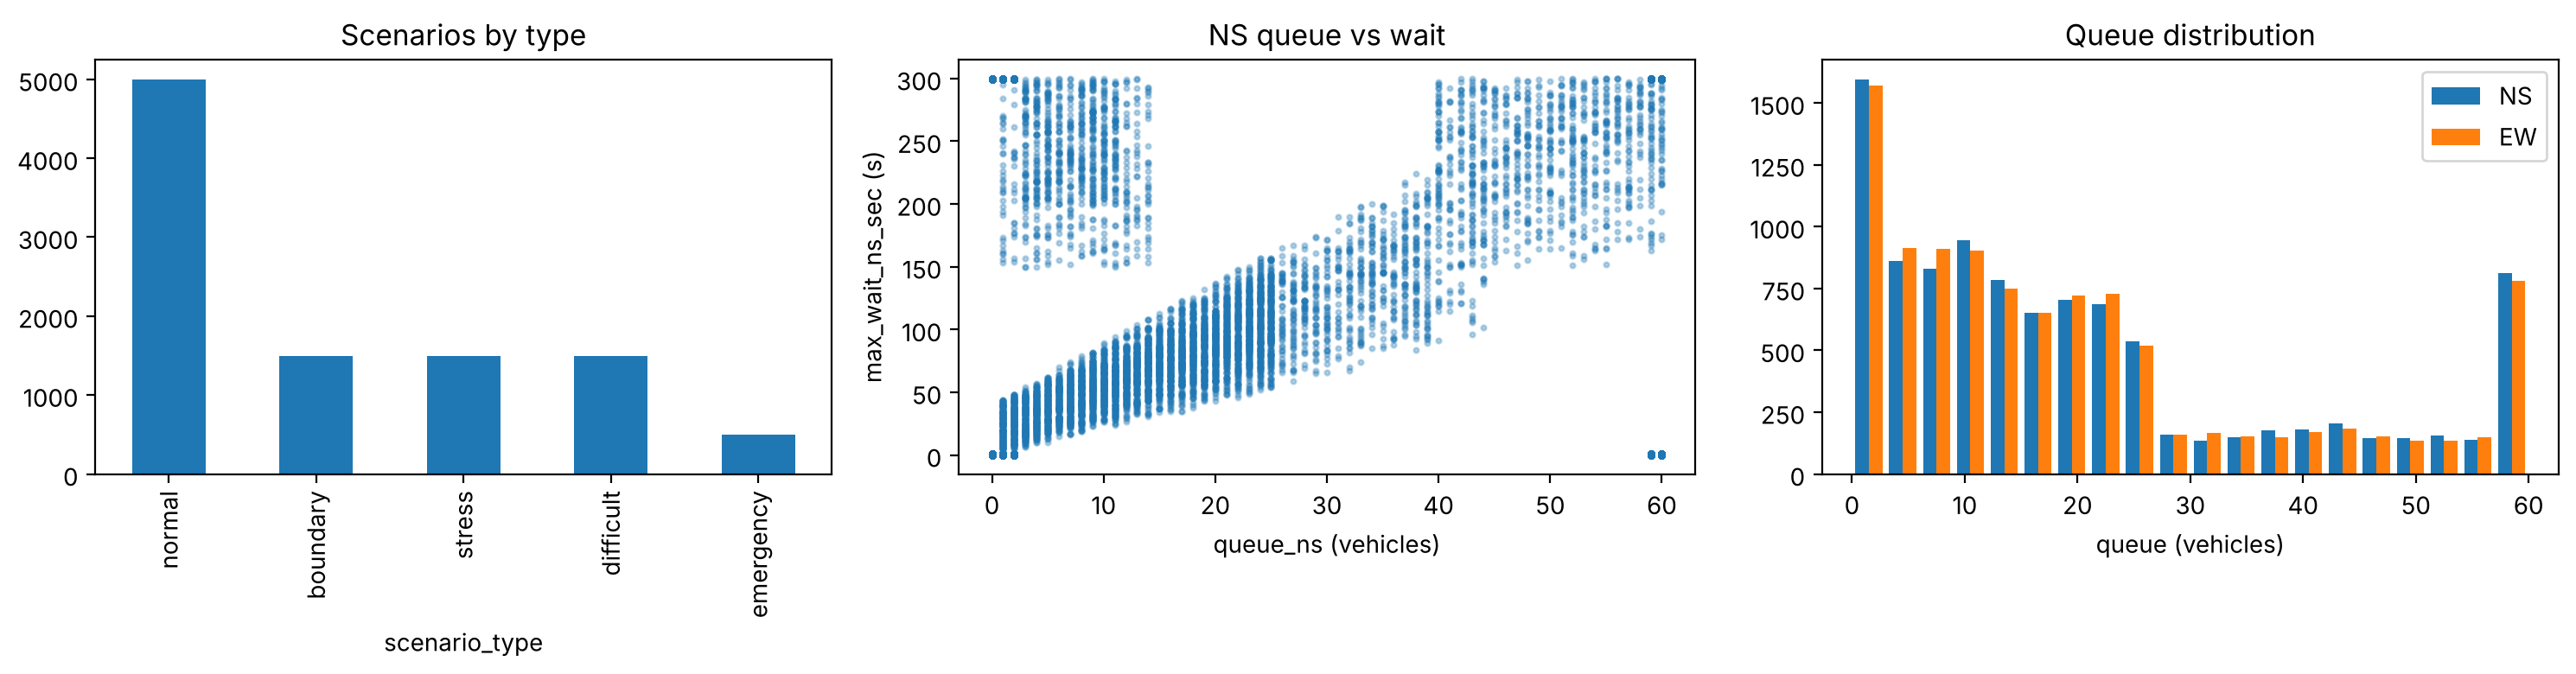

In [5]:
RESULTS = PROJECT_ROOT / "results" / "step2"
RESULTS.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["scenario_type"].value_counts().plot.bar(ax=axes[0], title="Scenarios by type")
axes[1].scatter(df["queue_ns"], df["max_wait_ns_sec"], s=4, alpha=0.3)
axes[1].set_xlabel("queue_ns (vehicles)"); axes[1].set_ylabel("max_wait_ns_sec (s)")
axes[1].set_title("NS queue vs wait")
axes[2].hist([df["queue_ns"], df["queue_ew"]], bins=20, label=["NS", "EW"])
axes[2].set_xlabel("queue (vehicles)"); axes[2].legend(); axes[2].set_title("Queue distribution")
plt.tight_layout()
plt.savefig(RESULTS / "scenario_overview.png", dpi=120)
plt.show()